# Opinion Dynamics Model with Stubborn Agents

This notebook simulates an opinion dynamics model over an Erdős-Rényi random network.

### Notebook Overview
1. **Imports**: Loads necessary libraries (`numpy`, `networkx`, and `matplotlib`).
2. **Parameters**: Sets configuration values like network size ($N = 20$), connection probability ($p = 0.3$), total steps ($50$), and number of stubborn agents ($2$).
3. **Graph Initialization**: Generates an Erdős-Rényi graph, sets random initial opinions for agents, designates a subset of stubborn agents (holding a constant opinion of `1.0`), and starts tracking the historical progress.
4. **Main Update Loop**: Runs a discrete-time consensus protocol where non-stubborn agents update their opinion to the average opinion of their neighbors at each step, while stubborn agents maintain their initial state.
5. **Visualization & Quantification**: Plots the evolution of opinions over time and outputs the final individual opinions as well as the average community opinion.

In [ ]:
# Imports
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
# parameters
N = 20
p = 0.3
num_steps = 50
num_stubborn = 2
p_fail = 0.2

In [ ]:
# Graph initialisation

# Create graph
G = nx.erdos_renyi_graph(N, p)

# Initialize opinions
x = np.random.rand(N)

# Select stubborn agents
stubborn_agents = np.random.choice(N, num_stubborn, replace=False)

# Set stubborn agents to truth
x[stubborn_agents] = 1.0

# Store history
history = [x.copy()]

In [ ]:
# Main loop

for k in range(num_steps):
    x_new = x.copy()

    for i in range(N):
        if i in stubborn_agents:
            x_new[i] = 1.0
        else:
            neighbors = list(G.neighbors(i))

            if len(neighbors) > 0:
                x_new[i] = np.mean(x[neighbors])

    x = x_new
    history.append(x.copy())

In [ ]:
# Convert history to array
history = np.array(history)

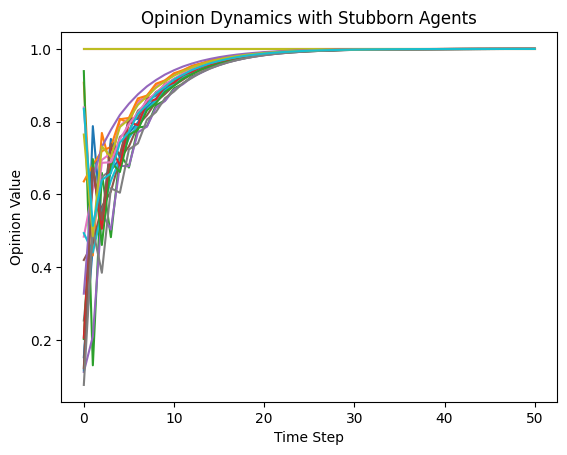

In [ ]:
# Plot results
plt.plot(history)
plt.xlabel("Time Step")
plt.ylabel("Opinion Value")
plt.title("Opinion Dynamics with Stubborn Agents")
plt.show()

In [ ]:
print("Final opinions:", x)
print("Average opinion:", np.mean(x))

# This helps us quantify results, not just see plots.

Final opinions: [0.99995257 0.99996278 0.99994228 1.         0.99994096 0.99994777
 0.99996371 0.99995698 1.         0.99995067 0.99995648 0.99996451
 0.99994866 0.999954   0.99996989 0.99995748 0.99995788 0.99994099
 0.99996199 0.99995631]
Average opinion: 0.9999592949304017
